# 📊 Ciclos Macro
Notebook 02: Modeling

## Preliminares

In [1]:
import pandas as pd
import numpy as np

# Algoritmos de Modelado No Supervisado y Reducción de Dimensionalidad
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

# Escalado
from sklearn.preprocessing import StandardScaler

# Métricas de Evaluación y Selección de Hiperparámetros (k clusters / n_components)
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

from src.config import clean_data_file
from src.modeling_functions import *

In [2]:
# Abrir fichero de datos
df = pd.read_parquet(clean_data_file)
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 188 entries, 2011-02-28 to 2026-09-30
Data columns (total 21 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   real_yield_10y                        188 non-null    float64
 1   vix_index                             188 non-null    float64
 2   gold                                  188 non-null    float64
 3   spy                                   188 non-null    float64
 4   oil_ret_1m                            188 non-null    float64
 5   gold_ret_1m                           188 non-null    float64
 6   spy_ret_1m                            188 non-null    float64
 7   dxy_broad_goods_ret_1m                188 non-null    float64
 8   vix_index_ret_1m                      188 non-null    float64
 9   oil_ret_12m                           188 non-null    float64
 10  gold_ret_12m                          188 non-null    float64
 11  

In [3]:
# Se separan las variables de precio
price_cols = ['gold', 'spy']
df_prices = df[price_cols].copy()

df = df.drop(price_cols, axis=1)
df_prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 188 entries, 2011-02-28 to 2026-09-30
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   gold    188 non-null    float64
 1   spy     188 non-null    float64
dtypes: float64(2)
memory usage: 4.4 KB


In [4]:
# Escalar variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# PCA: Reducción de dimensionalidad a 3 factores principales
pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"Varianza explicada por componente: {pca.explained_variance_ratio_}")

Varianza explicada por componente: [0.19478426 0.16926945 0.13180265]


In [5]:
# Cargas por componente
loadings_3d = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2', 'PC3'],
    index=df.columns,
)
print("Cargas factoriales por componente:")
print(loadings_3d.round(3))

Cargas factoriales por componente:
                                        PC1    PC2    PC3
real_yield_10y                        0.009 -0.207 -0.411
vix_index                            -0.294  0.297  0.070
oil_ret_1m                            0.260  0.089  0.055
gold_ret_1m                           0.150  0.078 -0.200
spy_ret_1m                            0.448 -0.031 -0.005
dxy_broad_goods_ret_1m               -0.361 -0.029  0.085
vix_index_ret_1m                     -0.361  0.079  0.037
oil_ret_12m                           0.081 -0.201  0.405
gold_ret_12m                          0.088  0.198 -0.155
spy_ret_12m                           0.222 -0.114  0.339
cpi_headline_lag1_ret_12m            -0.116 -0.252  0.027
industrial_production_lag1_ret_12m   -0.070 -0.418  0.211
m2_money_supply_lag1_ret_12m          0.057  0.329  0.470
real_yield_10y_change_1m             -0.208 -0.107  0.082
st_louis_financial_stress_change_1m  -0.375 -0.010  0.030
unemployment_rate_lag1_change_12m    

Se observa que cada uno de los 3 ejes se ha especializado de forma casi ortogonal en una dimensión concreta del sistema financiero y macroeconómico:

**PC1: Eje de Sentimiento de Mercado (Risk-On / Risk-Off a corto plazo)**

Separa los períodos de euforia y expansión bursátil de los shocks inmediatos de liquidez y aversión al riesgo.
* Cargas positivas dominantes: `spy_ret_1m` / `oil_ret_1m` / `gold_ret_1m`
* Cargas negativas dominantes: `st_louis_financial_stress_change_1m` / `dxy_broad_goods_ret_1m` / `vix_index_ret_1m`

**PC2: Ciclo Económico Real (Deterioro del Empleo vs. Expansión Industrial y Tipos)**

Mira la salud del mercado laboral frente a la producción y la respuesta de la Fed.
* Cargas positivas dominantes: `unemployment_rate_lag1_change_12m` / `m2_money_supply_lag1_ret_12m` / `st_louis_financial_stress_yeo`
* Cargas negativas dominantes: `industrial_production_lag1_ret_12m` / `fed_funds_rate_lag1_change_12m` / `cpi_headline_lag1_ret_12m`

**PC3: Régimen de Liquidez Monetaria y Retorno de Activos Reales**

Captura la oferta de dinero en el sistema frente al costo real del capital, y cómo eso impulsa las tendencias a 12 meses de los activos.
* Cargas positivas dominantes: `m2_money_supply_lag1_ret_12m` / `oil_ret_12m` / `spy_ret_12m`
* Cargas negativas dominantes: `real_yield_10y` / `fed_funds_rate_lag1_change_12m` / `unemployment_rate_lag1_change_3m_yeo`


In [6]:
# K-Means sobre el espacio PCA
kmeans = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_pca)

# Definir y entrenar modelo Gaussian Mixture
gmm = GaussianMixture(
    n_components=4,
    covariance_type="full",  # 'full' permite covarianzas cruzadas entre variables
    n_init=5,
    random_state=42,
)
gmm.fit(X_pca)
gmm_labels = gmm.predict(X_pca)
gmm_probs = gmm.predict_proba(X_pca)  # Probabilidad de pertenecer a cada régimen

# Evaluación de la calidad del agrupamiento
print(f"Silhouette Score (K-Means): {silhouette_score(X_pca, kmeans_labels):.4f}")
print(f"Silhouette Score (GMM):     {silhouette_score(X_pca, gmm_labels):.4f}")
print(f"GMM BIC Score:              {gmm.bic(X_pca):.2f}")  # Menor BIC = mejor ajuste

Silhouette Score (K-Means): 0.3547
Silhouette Score (GMM):     0.3223
GMM BIC Score:              2085.92


In [7]:
# Medias por cluster
df_analysis = df.copy()
df_analysis['regime'] = gmm_labels

profile = df_analysis.groupby('regime').mean().T
print("\nPerfil macro por Régimen:")
print(profile.round(3))


Perfil macro por Régimen:
regime                                     0       1       2       3
real_yield_10y                        -0.591   0.642   1.618  -0.812
vix_index                             26.788  16.321  18.301  26.902
oil_ret_1m                            -0.024   0.005  -0.016   0.112
gold_ret_1m                           -0.005   0.008   0.012   0.010
spy_ret_1m                            -0.027   0.013   0.005   0.039
dxy_broad_goods_ret_1m                 0.015   0.001   0.002  -0.007
vix_index_ret_1m                       0.323  -0.001   0.027  -0.041
oil_ret_12m                            0.422   0.016  -0.011   0.135
gold_ret_12m                           0.029   0.102   0.064   0.232
spy_ret_12m                            0.181   0.133   0.050   0.182
cpi_headline_lag1_ret_12m              0.049   0.022   0.050   0.012
industrial_production_lag1_ret_12m     0.043   0.011   0.002  -0.068
m2_money_supply_lag1_ret_12m           0.113   0.057  -0.009   0.223
real_yi

## Análisis de cada cluster
**Régimen 0: Sobrecalentamiento Inflacionario y Tensión de Mercado**

Es una economía que venía creciendo a buen ritmo ($\text{IndPro} \ \text{YoY} = +4.3\%$ y desempleo contrayéndose $\Delta 12\text{m} = -3.01$), pero donde las materias primas se dispararon ($\text{Oil} \ \text{YoY} = +42.2\%$) empujando la inflación al alza ($\text{CPI} \ \text{YoY} = 4.9\%$).

**Régimen 1: Expansión Sostenida**

Es el régimen de estabilidad por excelencia, con inflación controlada y variación de tasas casi nula. La volatilidad es baja y los activos de riesgo con avances consistentes ($\text{SPY} \ \text{YoY} = +13.3\%$, $\text{Gold} \ \text{YoY} = +10.2\%$).

**Régimen 2: Restricción / Ajuste Cuantitativo**

La tasa de la Fed sube a un ritmo de $+2.56$ puntos porcentuales por año, la tasa real a 10 años se sitúa en un nivel fuertemente restrictivo ($+1.62\%$) y la masa monetaria entra en territorio de contracción neta ($\text{M2} \ \text{YoY} = -0.9\%$) para combatir una inflación del $5.0\%$. El retorno del S&P 500 se desacelera, mientras que el petróleo se estanca ($-1.1\%$) y la actividad industrial se plancha ($+0.2\%$). Es el régimen de "apretón de liquidez".

**Régimen 3: Shock Recesivo & Estímulo de Emergencia**

Colapso de la economia real, con el desempleo aumentando año a año mientras la produccion industrial se desploma. La Reserva Federal responde con recorte de tasas e inyección de masa monetaria ($\text{M2} \ \text{YoY} = +22.3\%$). El VIX promedio es elevado, con el oro actuando como el gran ganador anual ($\text{Gold} \ \text{YoY} = +23.2\%$).


In [8]:
print("Distribución de meses por régimen:")
print(df_analysis['regime'].value_counts().sort_index())

Distribución de meses por régimen:
regime
0     16
1    135
2     24
3     13
Name: count, dtype: int64


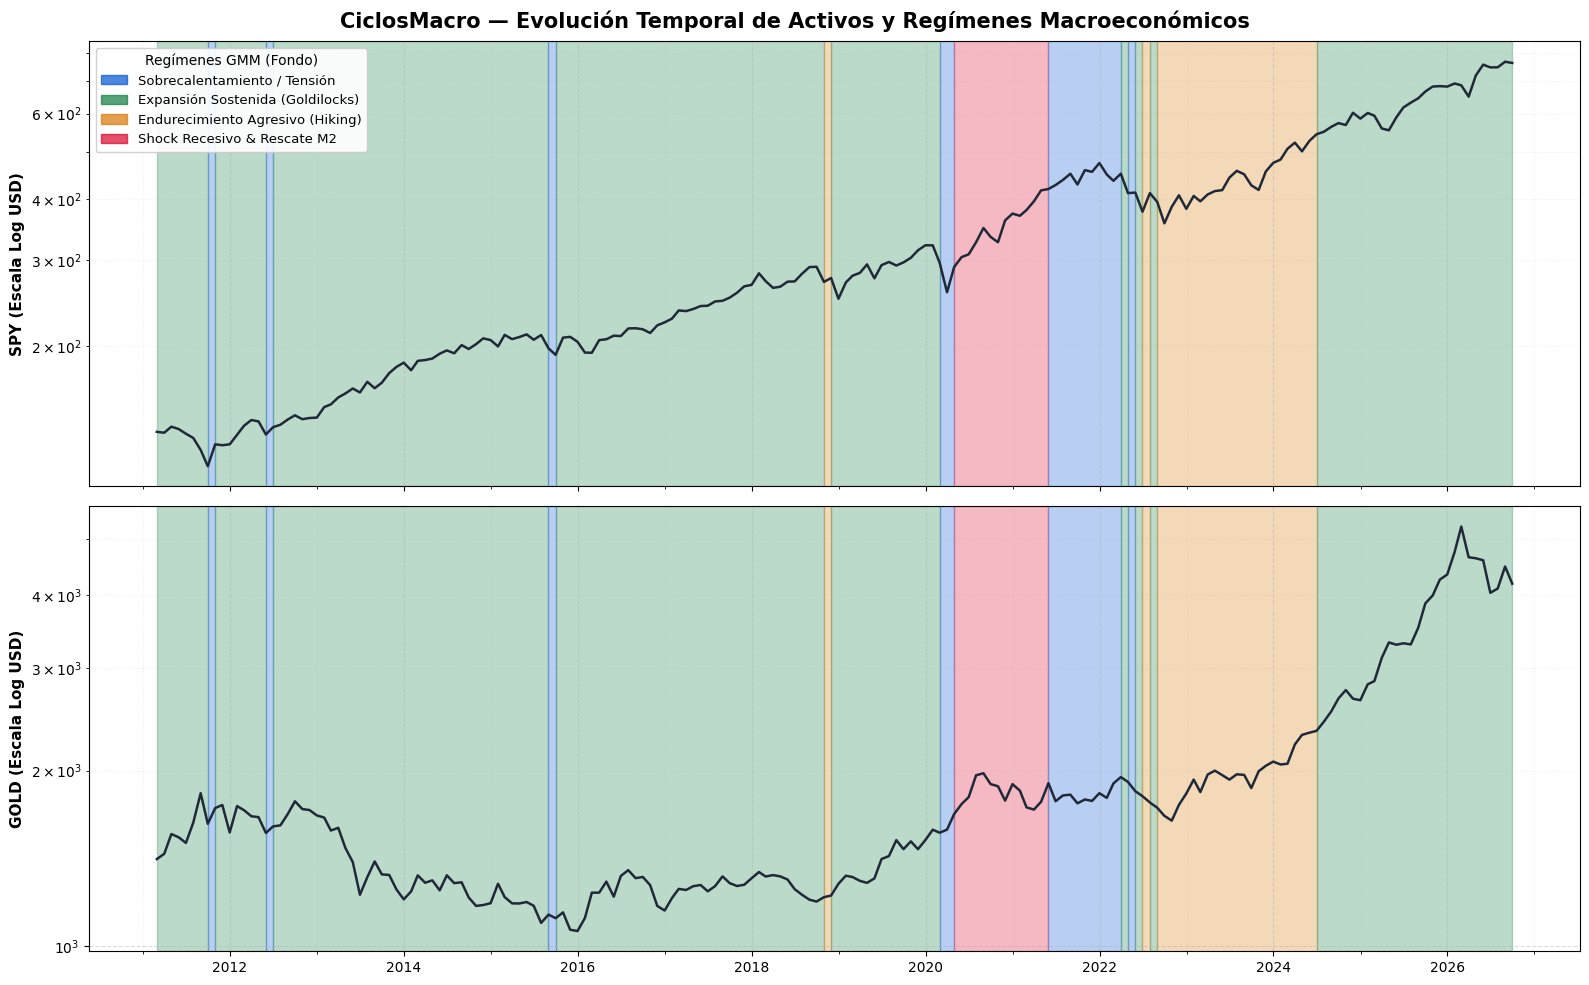

In [9]:
# 1. Extraer las etiquetas del modelo GMM 3D ajustado
gmm_regimes = pd.Series(gmm.predict(X_pca), index=df.index)

# 2. Llamar a la función pasando el dataframe original de precios mensuales
fig, axes = plot_regimes_timeline(
    df_prices=df_prices,  # DataFrame con las columnas 'spy' y 'gold'
    regime_series=gmm_regimes,
    assets=["spy", "gold"],
    figsize=(16, 10),
    log_scale=True,
)